# Waves: forcing, response time and memory

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/30-waves.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/30-waves.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `4f092c0ecb0216ee6b2adf3eb5243e63240ac52e76efcc09cc53d2b66f91d7d6`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Waves: forcing, response time and memory

**Lesson 30 · Original synthetic data · Independent educational project**

## Objectives

Drive a response model with wind; distinguish an equilibrium target from a delayed state.

[Previous](29-land.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/30-waves.ipynb) · [Next](31-sea-ice.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=30-waves.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

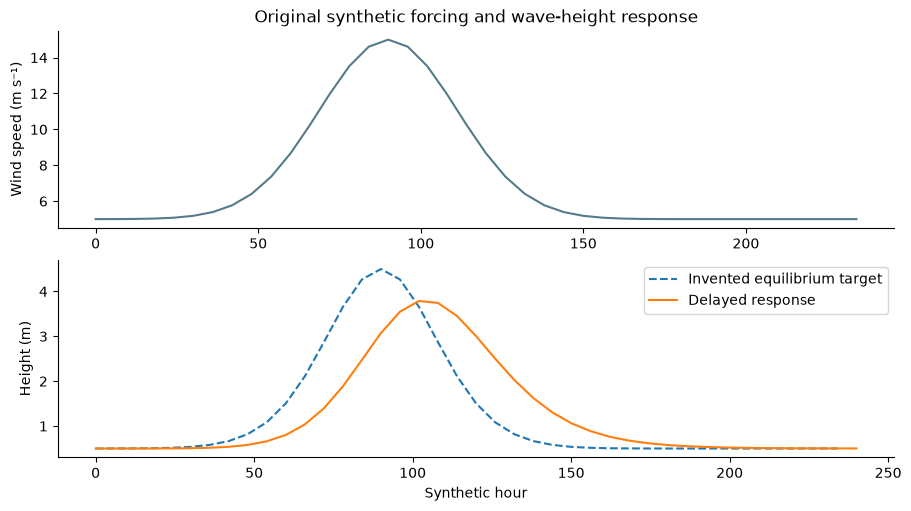

Wind maximum at 90 h; height maximum at 102 h


In [2]:
hour = np.arange(0, 240, 6)
wind = 5 + 10*np.exp(-((hour-90)/30)**2)
# Invented coefficient 0.02 s²/m maps wind squared to a target height in m.
# It is chosen for this exercise, not fitted to observations or a wave model.
target = .02*wind**2
dt_hours, response_hours = 6., 18.
fraction = dt_hours/response_hours
height = np.zeros(len(hour)+1)
height[0] = target[0]
for i in range(len(hour)):
    height[i+1] = height[i] + fraction*(target[i]-height[i])
assert 0 < fraction <= 1
assert np.all(height >= 0) and height.max() <= target.max()
assert np.allclose(np.diff(height), fraction*(target-height[:-1]))
constant_response = np.zeros(41)
for i in range(40):
    constant_response[i+1] = constant_response[i]+fraction*(2-constant_response[i])
analytic = 2*(1-(1-fraction)**np.arange(41))
assert np.allclose(constant_response, analytic)
assert abs(2-constant_response[-1]) < abs(2-constant_response[0])
fig, axes = plt.subplots(2, 1, figsize=(9, 5), constrained_layout=True)
axes[0].plot(hour, wind, color="#557b8a")
axes[0].set(ylabel="Wind speed (m s⁻¹)", title="Original synthetic forcing and wave-height response")
axes[1].plot(hour, target, "--", label="Invented equilibrium target")
axes[1].plot(np.r_[hour, hour[-1]+6], height, label="Delayed response")
axes[1].set(xlabel="Synthetic hour", ylabel="Height (m)")
axes[1].legend(); plt.show()
print(f"Wind maximum at {hour[np.argmax(wind)]} h; height maximum at {6*np.argmax(height)} h")

## Exercise

Try response times of 6, 18 and 48 hours. Compare the peak and delay. Explain why the condition dt/response_time ≤ 1 matters for this update.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

ECMWF's wave ML component connects atmospheric forcing with wave dynamics. This scalar relaxation equation only illustrates memory and forcing: it has no spectrum, propagation, fetch, bathymetry or wave-current interaction. Its coefficients are invented, and its height is not a validated significant-wave-height forecast. It neither runs the official AI wave model nor retrieves AIFS output.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/ml-earth-system-components/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).